---

# Initialization <a name="2"></a>

---

## Import Libraries

Every import of the notebook is kept in this cell.

In [65]:
#!pip install matplotlib numpy pandas scikit-learn

In [66]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler


## Settings

Paths and shared constants are kept in this class.

In [67]:
class Settings:
    SEED = 42
    DATA_DIR = Path(".")
    OUTPUT_DIR = Path("output")

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [68]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [69]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding <a name="3"></a>

---

## Explore Data
Memahami nya seperti memahami dia


In [70]:
print(train_df.shape)
train_df.dtypes

(27373, 19)


id                              str
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
meal_package                    str
needs_parking               float64
room_category                   str
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
booking_channel                 str
is_returning_guest            int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr            float64
special_requests            float64
is_canceled                   int64
dtype: object

In [71]:
train_df.head()

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


In [72]:
train_df.describe()

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


#### Distribusi Fitur Kategorikal

In [73]:
train_df["meal_package"].value_counts()


meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
Full Board        4
Name: count, dtype: int64

In [74]:
train_df["room_category"].value_counts()

room_category
Type B    20447
Type G     4396
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64

In [75]:
train_df["booking_channel"].value_counts()

booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64

####  Distribusi is_cancelled

In [76]:
print(train_df["is_canceled"].value_counts())
print(train_df["is_canceled"].value_counts(normalize=True))

is_canceled
0    18404
1     8969
Name: count, dtype: int64
is_canceled
0    0.672341
1    0.327659
Name: proportion, dtype: float64


In [77]:
pd.crosstab(
    train_df["booking_channel"],
    train_df["is_canceled"],
    normalize="index"
)

is_canceled,0,1
booking_channel,,
Airline,0.693182,0.306818
Complimentary,1.000000,0.000000
Corporate,0.884997,0.115003
Offline Agent,0.698492,0.301508
Online Travel Agent,0.636343,0.363657


In [78]:
pd.crosstab(
    train_df["meal_package"],
    train_df["is_canceled"],
    normalize="index"
)

is_canceled,0,1
meal_package,,
Breakfast,0.688562,0.311438
Full Board,0.750000,0.250000
Half Board,0.540589,0.459411
Room Only,0.661998,0.338002


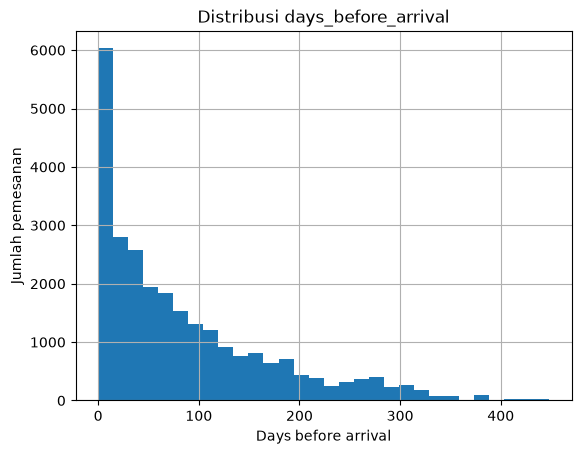

In [79]:
train_df["days_before_arrival"].hist(bins=30)
plt.xlabel("Days before arrival")
plt.ylabel("Jumlah pemesanan")
plt.title("Distribusi days_before_arrival")
plt.show()

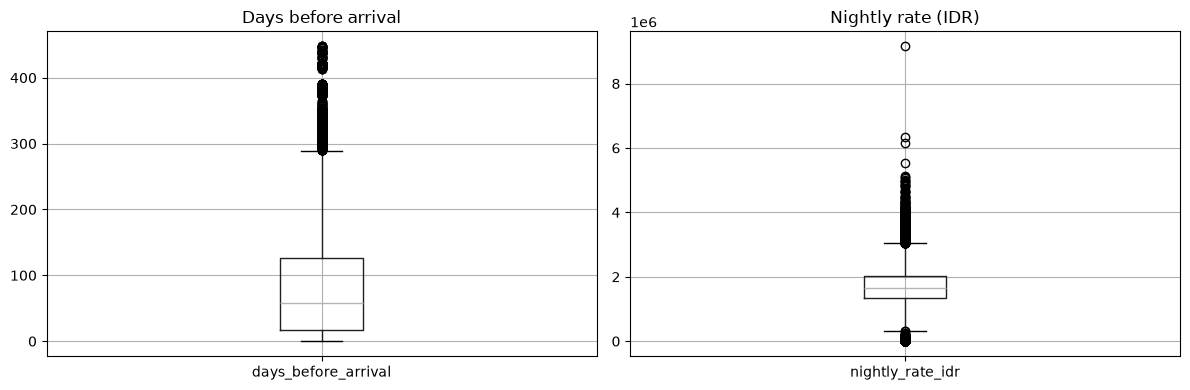

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_df.boxplot(column="days_before_arrival", ax=axes[0])
axes[0].set_title("Days before arrival")

train_df.boxplot(column="nightly_rate_idr", ax=axes[1])
axes[1].set_title("Nightly rate (IDR)")

plt.tight_layout()
plt.show()

In [81]:
train_df.groupby("is_canceled")["days_before_arrival"].describe()

,count,mean,std,min,25%,50%,75%,max
is_canceled,,,,,,,,
0,17631.0,58.913221,63.722946,0.0,10.0,38.0,86.0,390.0
1,8619.0,139.518622,99.195754,0.0,55.0,123.0,205.5,448.0


## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [82]:
feature_cols = test_df.columns

missing_summary = pd.DataFrame({
    "train": train_df[feature_cols].isna().sum(),
    "test": test_df.isna().sum()
})

missing_summary[missing_summary.sum(axis=1) > 0]

,train,test
num_adults,809,180
num_children,3035,747
meal_package,1760,442
needs_parking,1082,247
room_category,1002,242
days_before_arrival,1123,290
nightly_rate_idr,2038,540
special_requests,2500,593


In [83]:
print("Duplikat baris train:", train_df.duplicated().sum())
print("ID duplikat train:", train_df["id"].duplicated().sum())

print("Duplikat baris test:", test_df.duplicated().sum())
print("ID duplikat test:", test_df["id"].duplicated().sum())


Duplikat baris train: 0
ID duplikat train: 0
Duplikat baris test: 0
ID duplikat test: 0


In [84]:
nonnegative_cols = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests",
]

train_df[nonnegative_cols].lt(0).sum()

num_adults                  0
num_children                0
weekend_nights              0
weekday_nights              0
days_before_arrival         0
prior_cancellations         0
prior_completed_bookings    0
nightly_rate_idr            0
special_requests            0
dtype: int64

In [85]:
print("num_adults = 0:", (train_df["num_adults"] == 0).sum())
print("arrival_month di luar 1–12:", (~train_df["arrival_month"].between(1, 12)).sum())
print("arrival_day di luar 1–31:", (~train_df["arrival_day"].between(1, 31)).sum())

num_adults = 0: 106
arrival_month di luar 1–12: 0
arrival_day di luar 1–31: 0


In [86]:
train_features = train_df.drop(columns="is_canceled")

print("Kolom train dan test sama:", train_features.columns.equals(test_df.columns))

for col in ["meal_package", "room_category", "booking_channel"]:
    unseen = set(test_df[col].dropna().unique()) - set(train_df[col].dropna().unique())
    print(f"{col}, kategori baru di test:", unseen)

Kolom train dan test sama: True
meal_package, kategori baru di test: set()
room_category, kategori baru di test: set()
booking_channel, kategori baru di test: set()


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [87]:
train_set, val_set = train_test_split(
    train_df,
    test_size=0.20,
    random_state=CFG.SEED,
    stratify=train_df["is_canceled"],
)

print(f"Training set:   {train_set.shape}")
print(f"Validation set: {val_set.shape}")
print("Proporsi target training:")
print(train_set["is_canceled"].value_counts(normalize=True).sort_index())
print("Proporsi target validation:")
print(val_set["is_canceled"].value_counts(normalize=True).sort_index())


Training set:   (21898, 19)
Validation set: (5475, 19)
Proporsi target training:
is_canceled
0    0.672345
1    0.327655
Name: proportion, dtype: float64
Proporsi target validation:
is_canceled
0    0.672329
1    0.327671
Name: proportion, dtype: float64


---

# Data Preparation <a name="5"></a>

---

## Select Data

In [88]:
TARGET_COL = "is_canceled"
ID_COL = "id"
feature_cols = [col for col in test_df.columns if col != ID_COL]

test_ids = test_df[ID_COL].copy()

X_train_raw = train_set[feature_cols].copy()
y_train = train_set[TARGET_COL].astype(int).copy()
X_val_raw = val_set[feature_cols].copy()
y_val = val_set[TARGET_COL].astype(int).copy()
X_test_raw = test_df[feature_cols].copy()

print("Jumlah fitur:", len(feature_cols))
print("Train:", X_train_raw.shape, y_train.shape)
print("Validation:", X_val_raw.shape, y_val.shape)
print("Test:", X_test_raw.shape)


Jumlah fitur: 17
Train: (21898, 17) (21898,)
Validation: (5475, 17) (5475,)
Test: (6844, 17)


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

In [89]:
train_zero_adults = X_train_raw["num_adults"].eq(0)
val_zero_adults = X_val_raw["num_adults"].eq(0)
test_zero_adults = X_test_raw["num_adults"].eq(0)

print("num_adults = 0 pada train:", int(train_zero_adults.sum()))
print("num_adults = 0 pada validation:", int(val_zero_adults.sum()))
print("num_adults = 0 pada test:", int(test_zero_adults.sum()))

X_train_raw.loc[train_zero_adults, "num_adults"] = np.nan
X_val_raw.loc[val_zero_adults, "num_adults"] = np.nan
X_test_raw.loc[test_zero_adults, "num_adults"] = np.nan

numeric_cols = X_train_raw.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train_raw.select_dtypes(exclude="number").columns.tolist()

numeric_fill_values = X_train_raw[numeric_cols].median()
categorical_fill_values = X_train_raw[categorical_cols].mode(dropna=True).iloc[0]

def impute_missing_values(data: pd.DataFrame) -> pd.DataFrame:
    result = data.copy()
    result[numeric_cols] = result[numeric_cols].fillna(numeric_fill_values)
    result[categorical_cols] = result[categorical_cols].fillna(categorical_fill_values)
    return result

X_train_imputed = impute_missing_values(X_train_raw)
X_val_imputed = impute_missing_values(X_val_raw)
X_test_imputed = impute_missing_values(X_test_raw)

print("Missing value setelah imputasi (train):", int(X_train_imputed.isna().sum().sum()))
print("Missing value setelah imputasi (validation):", int(X_val_imputed.isna().sum().sum()))
print("Missing value setelah imputasi (test):", int(X_test_imputed.isna().sum().sum()))

num_adults = 0 pada train: 84
num_adults = 0 pada validation: 22
num_adults = 0 pada test: 22
Missing value setelah imputasi (train): 0
Missing value setelah imputasi (validation): 0
Missing value setelah imputasi (test): 0


### Duplicates

In [90]:
print("Duplikat train:", int(train_set.duplicated().sum()))
print("Duplikat validation:", int(val_set.duplicated().sum()))
print("Duplikat test:", int(test_df.duplicated().sum()))

X_train_clean = X_train_imputed.copy()
X_val_clean = X_val_imputed.copy()
X_test_clean = X_test_imputed.copy()


Duplikat train: 0
Duplikat validation: 0
Duplikat test: 0


### Outliers

In [91]:
outlier_cols = [
    "num_children", "weekend_nights", "weekday_nights",
    "days_before_arrival", "prior_cancellations",
    "prior_completed_bookings", "nightly_rate_idr", "special_requests",
]
outlier_counts = {}

for col in outlier_cols:
    values = X_train_raw[col].dropna()
    if col == "nightly_rate_idr":
        values = values[values > 0]
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    source = X_train_raw[col]
    eligible = source.notna()
    if col == "nightly_rate_idr":
        eligible &= source > 0
    outlier_counts[col] = int((eligible & ((source < lower) | (source > upper))).sum())

pd.Series(outlier_counts, name="kandidat_outlier_IQR")


num_children                1613
weekend_nights                13
weekday_nights               201
days_before_arrival          755
prior_cancellations          183
prior_completed_bookings     478
nightly_rate_idr             574
special_requests             456
Name: kandidat_outlier_IQR, dtype: int64

### Data Errors

In [92]:
negative_counts = train_set[numeric_cols].lt(0).sum()

binary_cols = ["needs_parking", "is_returning_guest", "is_canceled"]
invalid_binary_counts = (
    (~train_set[binary_cols].isin([0, 1]) & train_set[binary_cols].notna()).sum()
)

arrival_dates = pd.to_datetime(
    train_set[["arrival_year", "arrival_month", "arrival_day"]]
    .rename(columns={
        "arrival_year": "year",
        "arrival_month": "month",
        "arrival_day": "day",
    }),
    errors="coerce",
)
invalid_arrival_dates = int(arrival_dates.isna().sum())

print("Nilai numerik negatif:", negative_counts[negative_counts > 0].to_dict())
print("Nilai biner di luar 0/1:", invalid_binary_counts[invalid_binary_counts > 0].to_dict())
print("Tanggal kedatangan tidak valid:", invalid_arrival_dates)

Nilai numerik negatif: {}
Nilai biner di luar 0/1: {}
Tanggal kedatangan tidak valid: 0


## Data Transformation

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [93]:
scaled_numeric_cols = X_train_clean.select_dtypes(include="number").columns.tolist()
scaler = StandardScaler()

X_train_scaled = X_train_clean.copy()
X_val_scaled = X_val_clean.copy()
X_test_scaled = X_test_clean.copy()

X_train_scaled[scaled_numeric_cols] = scaler.fit_transform(X_train_clean[scaled_numeric_cols])
X_val_scaled[scaled_numeric_cols] = scaler.transform(X_val_clean[scaled_numeric_cols])
X_test_scaled[scaled_numeric_cols] = scaler.transform(X_test_clean[scaled_numeric_cols])

print("Jumlah fitur numerik yang distandardisasi:", len(scaled_numeric_cols))


Jumlah fitur numerik yang distandardisasi: 14


### Encoding

This part covers the numeric representation of categorical attributes.

In [94]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train_scaled[categorical_cols])

encoded_feature_names = encoder.get_feature_names_out(categorical_cols)

def combine_scaled_and_encoded(data: pd.DataFrame) -> pd.DataFrame:
    numeric_part = data[scaled_numeric_cols].copy()
    categorical_array = encoder.transform(data[categorical_cols])
    categorical_part = pd.DataFrame(
        categorical_array,
        columns=encoded_feature_names,
        index=data.index,
    )
    return pd.concat([numeric_part, categorical_part], axis=1)

X_train_encoded = combine_scaled_and_encoded(X_train_scaled)
X_val_encoded = combine_scaled_and_encoded(X_val_scaled)
X_test_encoded = combine_scaled_and_encoded(X_test_scaled)

print("Bentuk fitur train:", X_train_encoded.shape)
print("Bentuk fitur validation:", X_val_encoded.shape)
print("Bentuk fitur test:", X_test_encoded.shape)


Bentuk fitur train: (21898, 30)
Bentuk fitur validation: (5475, 30)
Bentuk fitur test: (6844, 30)


### Class Balance

In [95]:
class_balance = pd.DataFrame({
    "jumlah": y_train.value_counts().sort_index(),
    "proporsi": y_train.value_counts(normalize=True).sort_index(),
})
class_balance.index.name = TARGET_COL
print("Distribusi sebelum oversampling:")
print(class_balance)

majority_indices = y_train[y_train == 0].index
minority_indices = y_train[y_train == 1].sample(
    n=len(majority_indices),
    replace=True,
    random_state=CFG.SEED,
).index
balanced_indices = majority_indices.append(minority_indices)
balanced_indices = pd.Series(balanced_indices).sample(
    frac=1,
    random_state=CFG.SEED,
).to_numpy()

X_train_final = X_train_encoded.loc[balanced_indices].reset_index(drop=True)
y_train_final = y_train.loc[balanced_indices].reset_index(drop=True)
X_val_final = X_val_encoded.copy()
X_test_final = X_test_encoded.copy()

print("Distribusi training setelah oversampling:")
print(y_train_final.value_counts().sort_index())


Distribusi sebelum oversampling:
             jumlah  proporsi
is_canceled                  
0             14723  0.672345
1              7175  0.327655
Distribusi training setelah oversampling:
is_canceled
0    14723
1    14723
Name: count, dtype: int64


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [96]:
X_train = X_train_final.to_numpy(dtype=float)
X_val = X_val_final.to_numpy(dtype=float)
X_test = X_test_final.to_numpy(dtype=float)
y_train = y_train_final.to_numpy(dtype=int)
y_val = y_val.to_numpy(dtype=int)

print("X_train, y_train:", X_train.shape, y_train.shape)
print("X_val, y_val:", X_val.shape, y_val.shape)
print("X_test:", X_test.shape)


X_train, y_train: (29446, 30) (29446,)
X_val, y_val: (5475, 30) (5475,)
X_test: (6844, 30)
